In [1]:
from volta.prelude import *
from volta.robot.states import States
from volta.planning.footsteps_planner import *
from volta.planning.ismpc import *
# from UtilsFunction.IntrinsicallyStableMPC.footstep_planner import *  # moved to legacy/ (not importable from volta)
from volta.planning.foot_trajectory_generator import *
# from temp_include import *  # moved to legacy/ (not importable from volta)
import time
import copy


In [2]:
com_high = 0.35
params = {
    'g': 9.81,
    'h': com_high,
    'foot_size': 0.05,
    'step_height': 0.02,
    'ss_duration': 70,
    'ds_duration': 30,
    'mpc_time_step': 0.01,
    'first_swing': 'rfoot',
    'µ': 0.5,
    'N': 100,
    'dof': 18,
}
params['eta'] = np.sqrt(params['g'] / params['h'])
initial = {
            'lfoot': {'pos': np.array([0,0,0,0,0.125,0]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(6)},
            'rfoot': {'pos': np.array([0,0,0,0,-0.125,0]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(6)},
            'com'  : {'pos': np.array([0,0,com_high]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(3)},
            'torso': {'pos': np.array([0,0,0,0]),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)},
            'base' : {'pos': np.array([0,0,0,0,0,0]),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)},
            'joint': {'pos': np.zeros(12),
                      'vel': np.zeros(12),
                      'acc': np.zeros(12)},
            'zmp'  : {'pos': np.zeros(3),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)}
        }
desired = copy.deepcopy(initial)
current = copy.deepcopy(initial)
# initialize footstep planner
# reference = [(0.1, 0., 0.0)] * 5 + [(0.2, 0., -0.1)] * 10 + [(0.1, 0., 0.)] * 10
reference = [(0.05, 0., 0.0)] * 10 + [(0.1, 0., -0.0)] * 10
# footstep_planner = FootstepPlanner(
#     reference,
#     initial['lfoot']['pos'],
#     initial['rfoot']['pos'],
#     params
#     )

# # initialize MPC controller
# mpc = Ismpc(
#     initial, 
#     footstep_planner, 
#     params
#     )

/home/tanawatp/Documents/Thesis_simulation/Simulation/temp_include.py:169: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_map.legend()


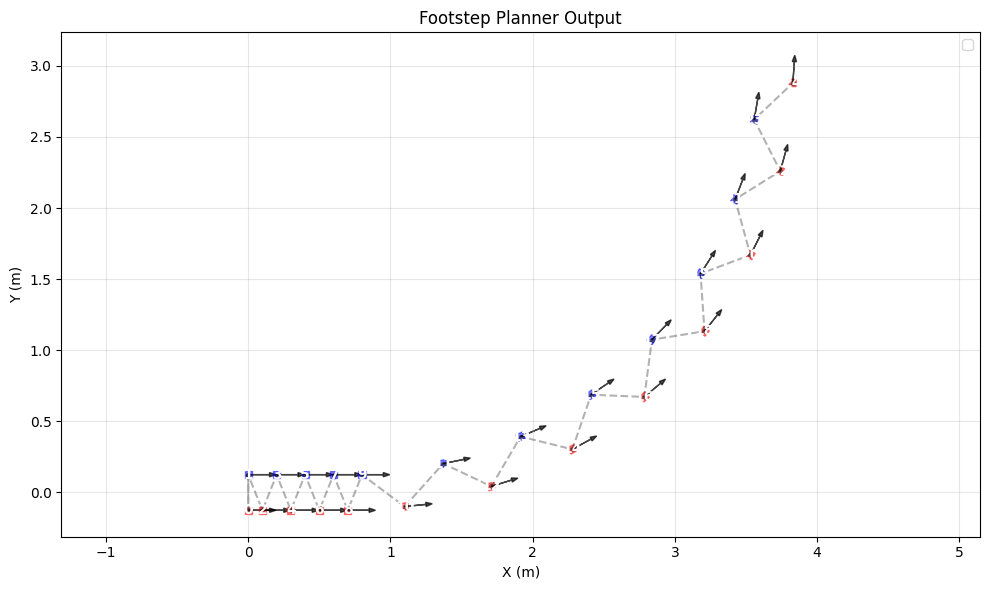

In [3]:
planner = FootstepsPlanner(params=params)

# Reference Velocity Function
def VRefCommand(t):
    if t < 8.0:
        return [0.1, 0.0, 0.0]
    else:
        return [0.5, 0.0, 0.1]
        
initial_pose = [0.0, 0.125, 0.0]

# Generate Plan
plan = planner.PlanFootsteps(initial_pose, VRefCommand, 25.0-2.0, 'lfoot')
# foot_trajtory_gen = FootTrajectoryGenerator(initial=initial,
#                                             footstep_planner=planner,
#                                             params=params)
# feet_traj = foot_trajtory_gen.generate_feet_trajectories_at_time(time=160)
PlotFootsteps(steps=plan,
              traj_x=None,
              traj_y=None,
              zmp_x=None,
              zmp_y=None,
              initial_pose=[0.0, 0.125, 0.0])

In [4]:
curr_timestep = 0
curr_time = 0.0
dt = 0.01
t = []
com_pos = []
com_vel = []
zmp_pos = []
zmp_vel = []
lfoot_pos = []
lfoot_ori = []

sim_time = 5.0


# Reference Velocity Function
def VRefCommand(t):
    # if t < 2.0:
    #     return [0.05, 0.0, 0.0]
    # elif t<4.0:
    #     return [0.1, 0.0, 0.0]
    # else:
    #     return [0.1, 0.0, 0.05]
    return [0.05, 0.00, 0.0]  
initial_pose = [0.0, 0.125, 0.0]

# Generate Plan
planner = FootstepsPlanner(params=params)
plan = planner.PlanFootsteps(initial_pose, VRefCommand, 6.0, 'lfoot')
mpc = Ismpc(
    initial, 
    planner, 
    params
    )
com_pos_lip = []
com_vel_lip = []
zmp_pos_lip = []
ex_LIP_states = np.zeros([9,1])
foot_trajtory_gen = FootTrajectoryGenerator(initial=initial,
                                            footstep_planner=planner,
                                            params=params)
Fx = []
while curr_time < sim_time:
    # print("="*30)
    # print(curr_time)
    lip_state, contact = mpc.solve(current, curr_timestep)
    t.append(curr_time)
    com_pos.append(lip_state['com']['pos'])
    com_vel.append(lip_state['com']['vel'])
    zmp_pos.append(lip_state['zmp']['pos'])
    zmp_vel.append(lip_state['zmp']['vel'])
    feet_traj = foot_trajtory_gen.generate_feet_trajectories_at_time(time=curr_timestep)
    lfoot_pos.append(feet_traj['rfoot']['pos'][3:])
    lfoot_ori.append(feet_traj['rfoot']['pos'][:3])

    # fx = mpc.A_lip @ ex_LIP_states[0:3] + mpc.B_lip * np.array([lip_state['zmp']['vel']]).T[0]
    # fy = mpc.A_lip @ ex_LIP_states[3:6] + mpc.B_lip * np.array([lip_state['zmp']['vel']]).T[1]
    # # fx = mpc.B_lip * np.array([lip_state['zmp']['vel']]).T[0]
    # # print("fx",fx)
    # # print("fx2",fx[2])
    # # Fx.append(fx[2][0])
    # # fy = mpc.B_lip * np.array([lip_state['zmp']['vel']]).T[1]
    # ex_LIP_states[0:3] = ex_LIP_states[0:3] + fx*dt
    # ex_LIP_states[3:6] = ex_LIP_states[3:6] + fy*dt
    com_pos_lip.append([ex_LIP_states[0][0],ex_LIP_states[3][0]])
    com_vel_lip.append([ex_LIP_states[1][0],ex_LIP_states[4][0]])
    zmp_pos_lip.append([ex_LIP_states[2][0],ex_LIP_states[5][0]])
    # print("X int",ex_LIP_states.T)
    current['com']['pos'] = lip_state['com']['pos']
    current['com']['vel'] = lip_state['com']['vel']
    current['com']['acc'] = lip_state['com']['acc'] 
    current['zmp']['pos'] = lip_state['zmp']['pos']   
    # current['com']['pos'] = np.array([ex_LIP_states[0][0], ex_LIP_states[3][0], com_high])
    # current['com']['vel'] = np.array([ex_LIP_states[1][0], ex_LIP_states[4][0], 0.0])
    # current['com']['acc'] = np.array([fx[2][0], fy[2][0], 0.0])
    # current['zmp']['pos'] = np.array([ex_LIP_states[2][0],ex_LIP_states[5][0],0.0])
    current['zmp']['vel'] = lip_state['zmp']['vel']
    curr_time += dt
    curr_timestep += 1

# Fx = np.array([Fx])

com_pos_lip = np.array(com_pos_lip).T
com_vel_lip = np.array(com_vel_lip).T
zmp_pos_lip = np.array(zmp_pos_lip).T
t = np.array(t)
com_pos = np.array(com_pos).T
com_vel = np.array(com_vel).T
zmp_pos = np.array(zmp_pos).T
zmp_vel = np.array(zmp_vel).T
lfoot_pos = np.array(lfoot_pos).T
lfoot_ori = np.array(lfoot_ori).T



In [5]:
com_pos_lip_x = com_pos_lip[0,:]
com_pos_lip_y = com_pos_lip[1,:]
com_vel_lip_x = com_vel_lip[0,:]
com_vel_lip_y = com_vel_lip[1,:]
zmp_pos_lip_x = zmp_pos_lip[0,:]
zmp_pos_lip_y = zmp_pos_lip[1,:]
com_pos_x = com_pos[0,:]
com_pos_y = com_pos[1,:]
com_vel_x = com_vel[0,:]
com_vel_y = com_vel[1,:]
zmp_pos_x = zmp_pos[0,:]
zmp_pos_y = zmp_pos[1,:]
zmp_vel_x = zmp_vel[0,:]
zmp_vel_y = zmp_vel[1,:]
lfoot_pos_x = lfoot_pos[0,:]
lfoot_pos_y = lfoot_pos[1,:]
lfoot_pos_z = lfoot_pos[2,:]
lfoot_ori_x = lfoot_ori[0,:]
lfoot_ori_y = lfoot_ori[1,:]
lfoot_ori_z = lfoot_ori[2,:]

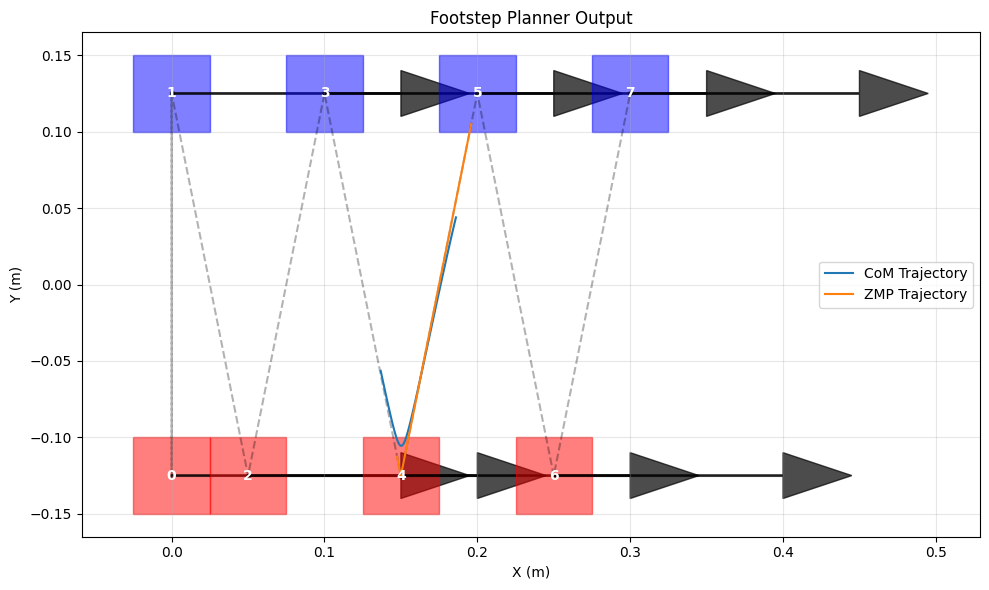

In [6]:
PlotFootsteps(steps=plan,
              traj_x=mpc.optimal_LIP_states[0,:],
              traj_y=mpc.optimal_LIP_states[3,:],
              zmp_x=mpc.optimal_LIP_states[2,:],
              zmp_y=mpc.optimal_LIP_states[5,:],
              initial_pose=[0.0, 0.125, 0.0])

In [36]:
def CalcXu(xd_c,x_c,eta):
    return x_c + xd_c/eta
def CalcXs(xd_c,x_c,eta):
    return x_c - xd_c/eta

X_U = []
Y_U = []
X_S = []
Y_S = []
for i in range(mpc.N):
    X_U.append(CalcXu(xd_c=mpc.optimal_LIP_states[1,i], x_c=mpc.optimal_LIP_states[0,i],eta=mpc.eta))
    Y_U.append(CalcXu(xd_c=mpc.optimal_LIP_states[4,i], x_c=mpc.optimal_LIP_states[3,i],eta=mpc.eta))
    X_S.append(CalcXs(xd_c=mpc.optimal_LIP_states[1,i], x_c=mpc.optimal_LIP_states[0,i],eta=mpc.eta))
    Y_S.append(CalcXs(xd_c=mpc.optimal_LIP_states[4,i], x_c=mpc.optimal_LIP_states[3,i],eta=mpc.eta))

In [8]:
def CalcXu(xd_c,x_c,eta):
    return x_c + xd_c/eta
def CalcXs(xd_c,x_c,eta):
    return x_c - xd_c/eta
X_Uf = []
Y_Uf = []
X_Sf = []
Y_Sf = []
for i in range(com_pos_x.shape[0]):
    X_Uf.append(CalcXu(xd_c=com_vel_x[i], x_c=com_pos_x[i],eta=mpc.eta))
    Y_Uf.append(CalcXu(xd_c=com_vel_y[i], x_c=com_pos_y[i],eta=mpc.eta))
    X_Sf.append(CalcXs(xd_c=com_vel_x[i], x_c=com_pos_x[i],eta=mpc.eta))
    Y_Sf.append(CalcXs(xd_c=com_vel_y[i], x_c=com_pos_y[i],eta=mpc.eta))

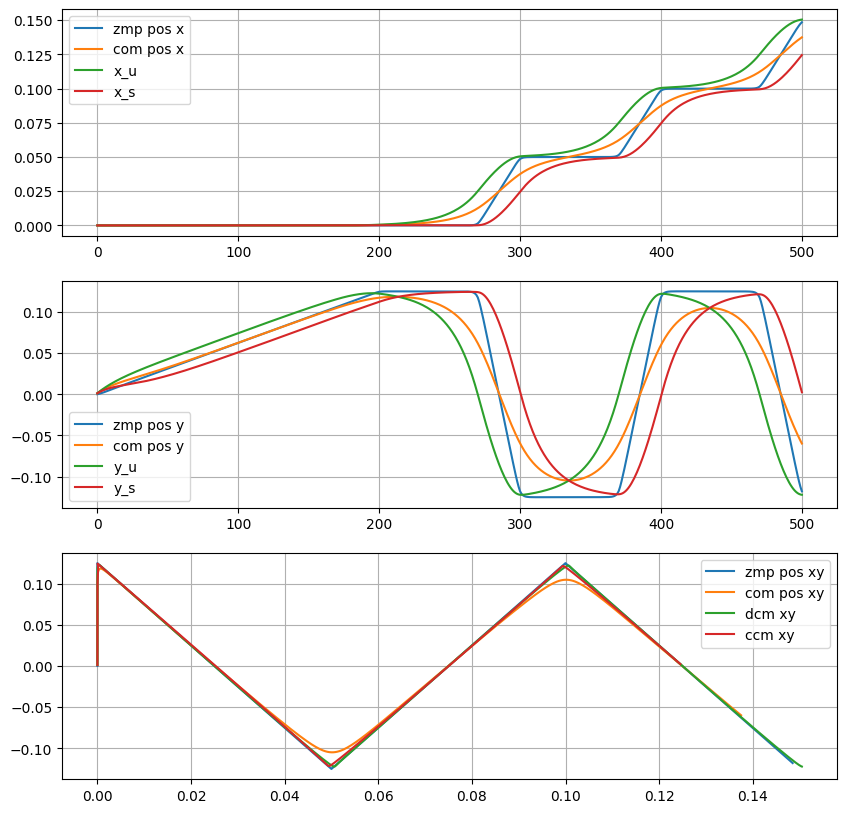

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(zmp_pos_x,label="zmp pos x")
axes[0].plot(com_pos_x,label="com pos x")
axes[0].plot(X_Uf,label="x_u")
axes[0].plot(X_Sf,label="x_s")
axes[1].plot(zmp_pos_y,label="zmp pos y")
axes[1].plot(com_pos_y,label="com pos y")
axes[1].plot(Y_Uf,label="y_u")
axes[1].plot(Y_Sf,label="y_s")
axes[2].plot(zmp_pos_x,zmp_pos_y,label="zmp pos xy")
axes[2].plot(com_pos_x,com_pos_y,label="com pos xy")
axes[2].plot(X_Uf,Y_Uf,label="dcm xy")
axes[2].plot(X_Sf,Y_Sf,label="ccm xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

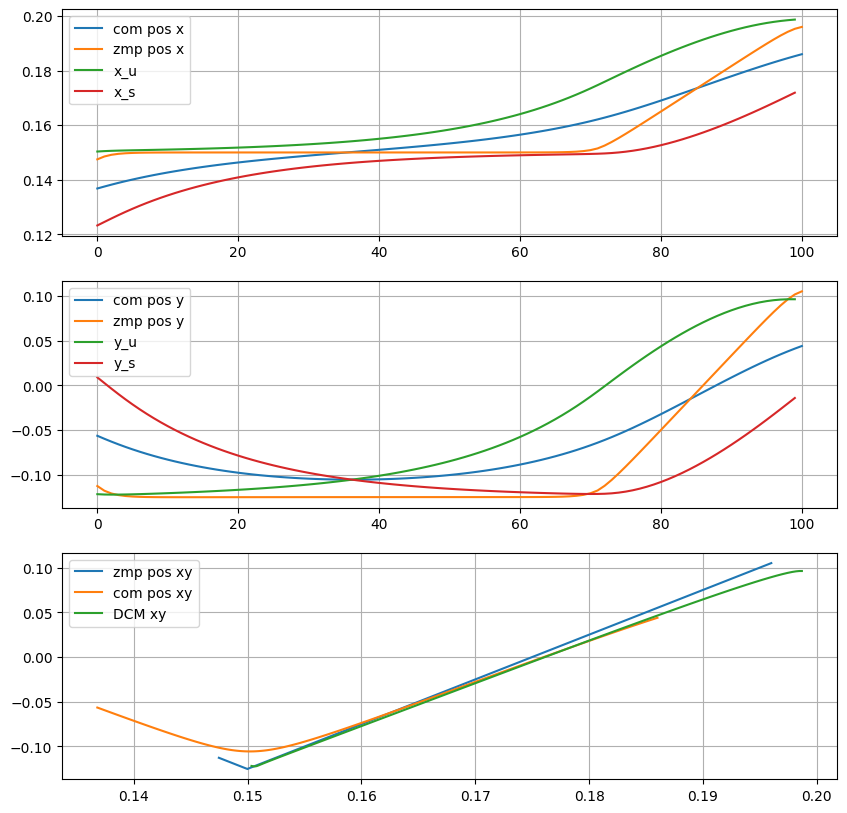

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(mpc.optimal_LIP_states[0,:],label="com pos x")
axes[1].plot(mpc.optimal_LIP_states[3,:],label="com pos y")
axes[0].plot(mpc.optimal_LIP_states[2,:],label="zmp pos x")
axes[1].plot(mpc.optimal_LIP_states[5,:],label="zmp pos y")
axes[0].plot(X_U,label="x_u")
axes[1].plot(Y_U,label="y_u")
axes[0].plot(X_S,label="x_s")
axes[1].plot(Y_S,label="y_s")
axes[2].plot(mpc.optimal_LIP_states[2,:],mpc.optimal_LIP_states[5,:],label="zmp pos xy")
axes[2].plot(mpc.optimal_LIP_states[0,:],mpc.optimal_LIP_states[3,:],label="com pos xy")
axes[2].plot(X_U,Y_U,label="DCM xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

Text(0, 0.5, 'xd')

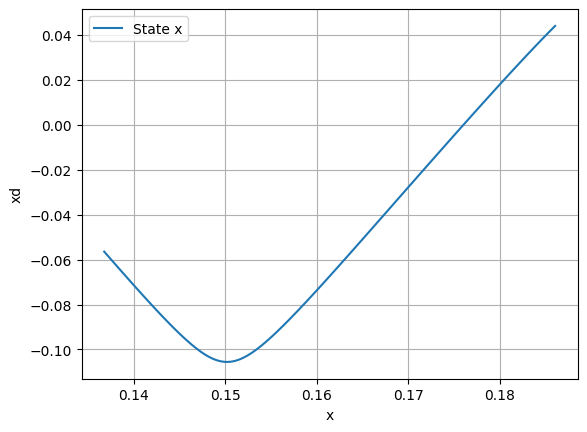

In [11]:
plt.plot(mpc.optimal_LIP_states[0,:],mpc.optimal_LIP_states[3,:],label="State x")
plt.legend()
plt.grid()
plt.xlabel("x")
plt.ylabel("xd")

Text(0, 0.5, 'yd')

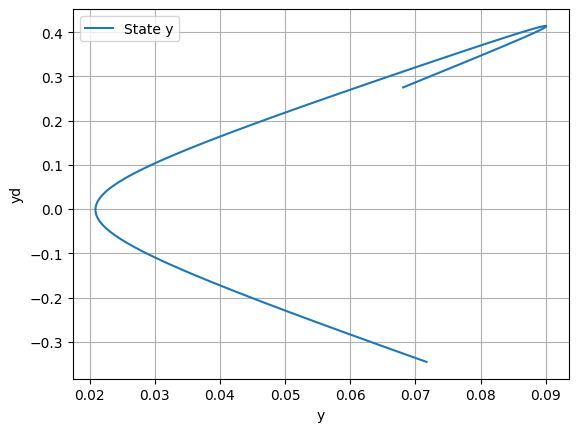

In [12]:
plt.plot(mpc.optimal_LIP_states[1,:],mpc.optimal_LIP_states[4,:],label="State y")
plt.legend()
plt.grid()
plt.xlabel("y")
plt.ylabel("yd")

In [13]:
def CalcXdu(xd_c,x_c,x_z,eta):
    print("xd_c=",xd_c)
    print("x_c=",x_c)
    print("x_z=",x_z)
    return xd_c + eta*(x_c-x_z)

In [14]:
mpc.optimal_zmp_vel.shape

(3, 100)

In [15]:
mpc.optimal_zmp_vel[0,0]

np.float64(0.1051371049787754)

In [16]:
mpc.optimal_zmp_vel[0,-1]

np.float64(0.06963528273532778)

In [17]:
# X axis
print("x axis")
xd_u_0 = CalcXdu(xd_c=com_vel_x[-2],x_c=com_pos_x[-2],x_z=zmp_pos_x[-2],eta=mpc.eta)
xd_u_N = CalcXdu(xd_c=mpc.optimal_LIP_states[1,-1], x_c=mpc.optimal_LIP_states[0,-1],x_z=mpc.optimal_LIP_states[2,-1],eta=mpc.eta)

print("xd_u[0] = ", xd_u_0)
print("xd_u[N] = ", xd_u_N)
print("-"*20)
# Y axis
print("y axis")
yd_u_0 = CalcXdu(xd_c=com_vel_y[-2],x_c=com_pos_y[-2],x_z=zmp_pos_y[-2],eta=mpc.eta)
yd_u_N = CalcXdu(xd_c=mpc.optimal_LIP_states[4,-1], x_c=mpc.optimal_LIP_states[3,-1],x_z=mpc.optimal_LIP_states[5,-1],eta=mpc.eta)

print("yd_u[0] = ", yd_u_0)
print("yd_u[N] = ", yd_u_N)

x axis
xd_c= 0.07171641227471404
x_c= 0.13679091694293477
x_z= 0.1474705323387681
xd_c= 0.0681292418630515
x_c= 0.18600973087414002
x_z= 0.19601133191888412
xd_u[0] =  0.015176374504282199
xd_u[N] =  0.015178748809224075
--------------------
y axis
xd_c= -0.3457133140756923
x_c= -0.05648545539261164
x_z= -0.11263107509190741
xd_c= 0.27527034219858887
x_c= 0.043920027007717743
x_z= 0.10504318278632264
yd_u[0] =  -0.04846707993873933
yd_u[N] =  -0.04832797181172971


In [18]:
mpc.eta

np.float64(5.294201680005346)

In [19]:
mpc.optimal_LIP_states[4,-1]

np.float64(0.27527034219858887)

In [20]:
mpc.optimal_LIP_states[4,-1]

np.float64(0.27527034219858887)

In [21]:
mpc.optimal_LIP_states[:,-1]

array([1.86009731e-01, 6.81292419e-02, 1.96011332e-01, 4.39200270e-02,
       2.75270342e-01, 1.05043183e-01, 3.50000000e-01, 2.77454304e-15,
       7.65654624e-18])

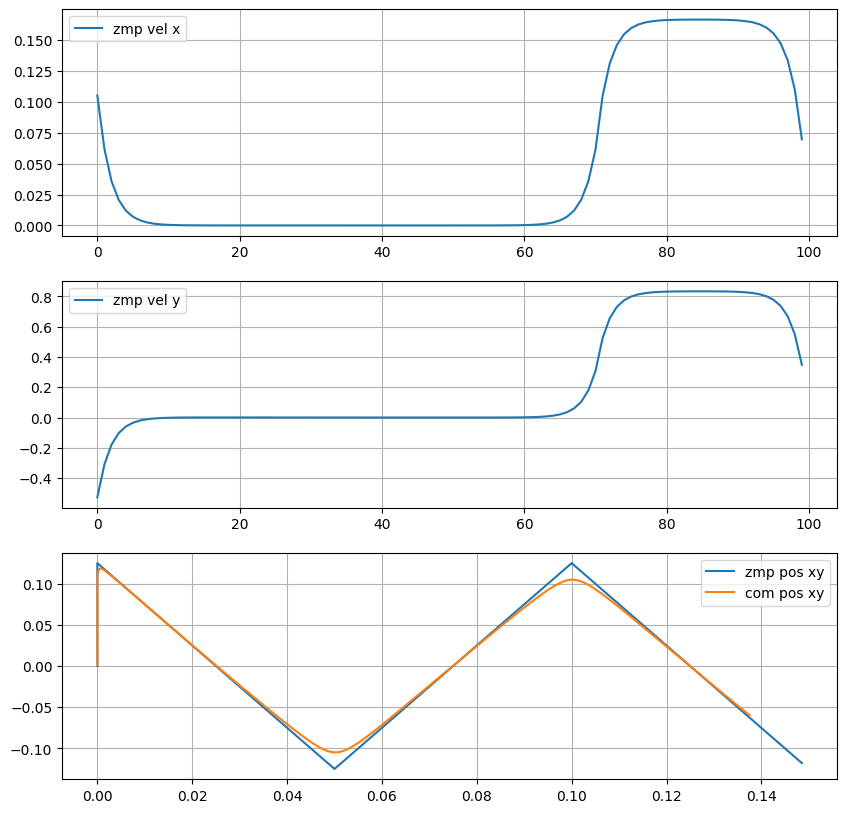

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(mpc.optimal_zmp_vel[0,:],label="zmp vel x")
# axes[0].plot(com_pos_x,label="com pos x")
axes[1].plot(mpc.optimal_zmp_vel[1,:],label="zmp vel y")
# axes[1].plot(com_pos_y,label="com pos y")
axes[2].plot(zmp_pos_x,zmp_pos_y,label="zmp pos xy")
axes[2].plot(com_pos_x,com_pos_y,label="com pos xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

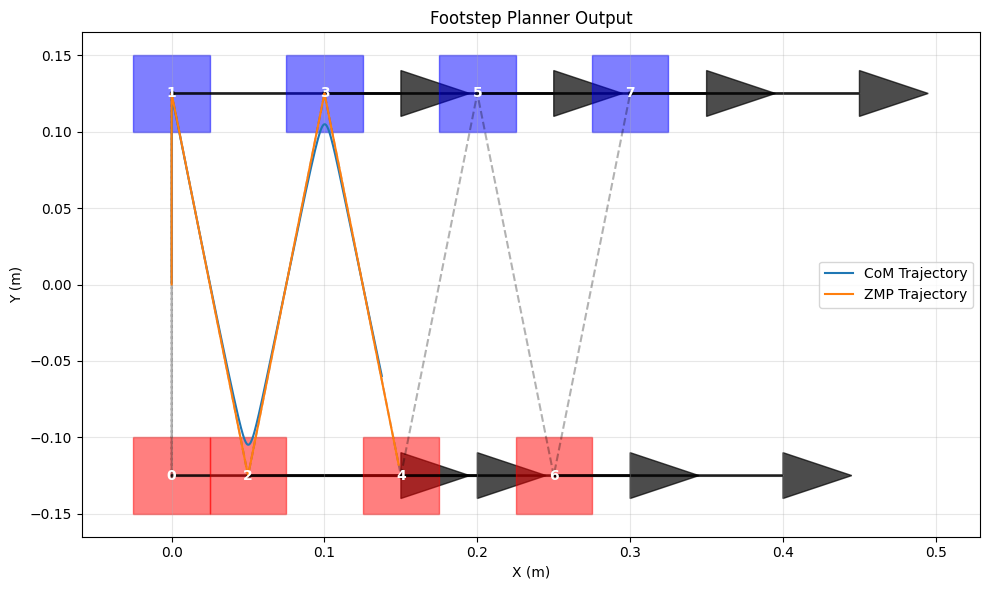

In [23]:
PlotFootsteps(steps=plan,
              traj_x=com_pos_x,
              traj_y=com_pos_y,
              zmp_x=zmp_pos_x,
              zmp_y=zmp_pos_y,
              initial_pose=[0.0, 0.125, 0.0])

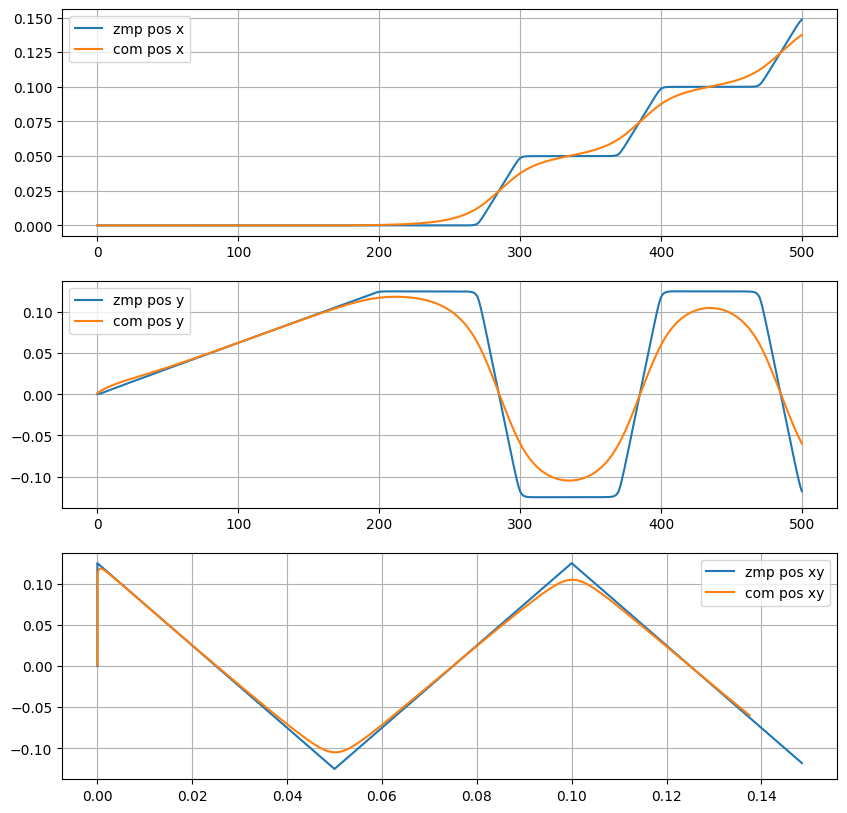

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(zmp_pos_x,label="zmp pos x")
axes[0].plot(com_pos_x,label="com pos x")
axes[1].plot(zmp_pos_y,label="zmp pos y")
axes[1].plot(com_pos_y,label="com pos y")
axes[2].plot(zmp_pos_x,zmp_pos_y,label="zmp pos xy")
axes[2].plot(com_pos_x,com_pos_y,label="com pos xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

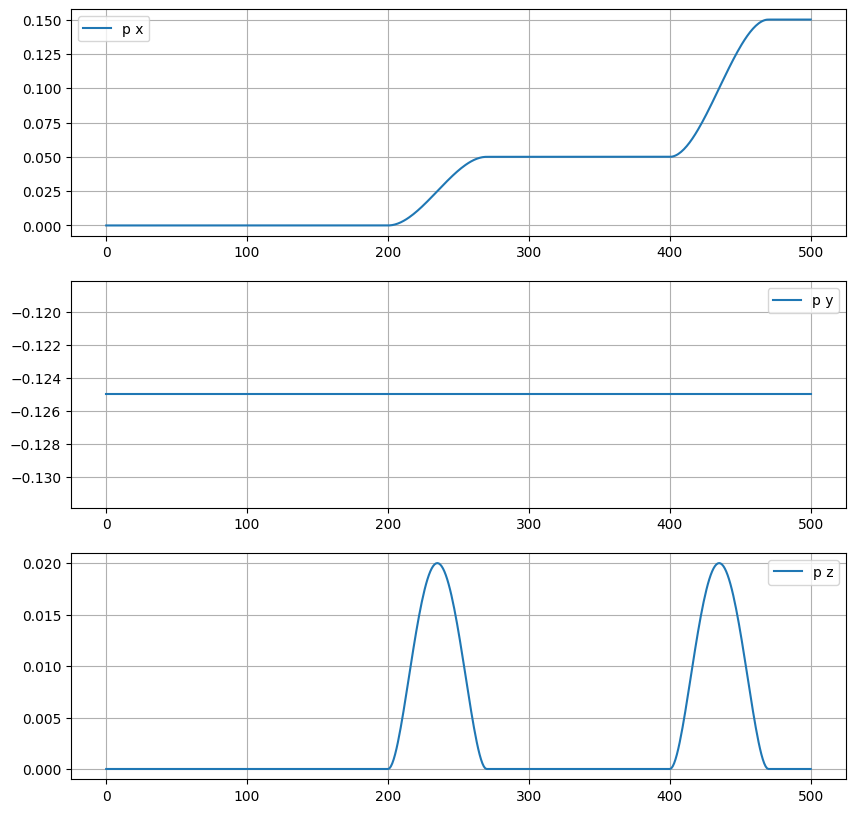

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(lfoot_pos_x,label="p x")
axes[1].plot(lfoot_pos_y,label="p y")
axes[2].plot(lfoot_pos_z,label="p z")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

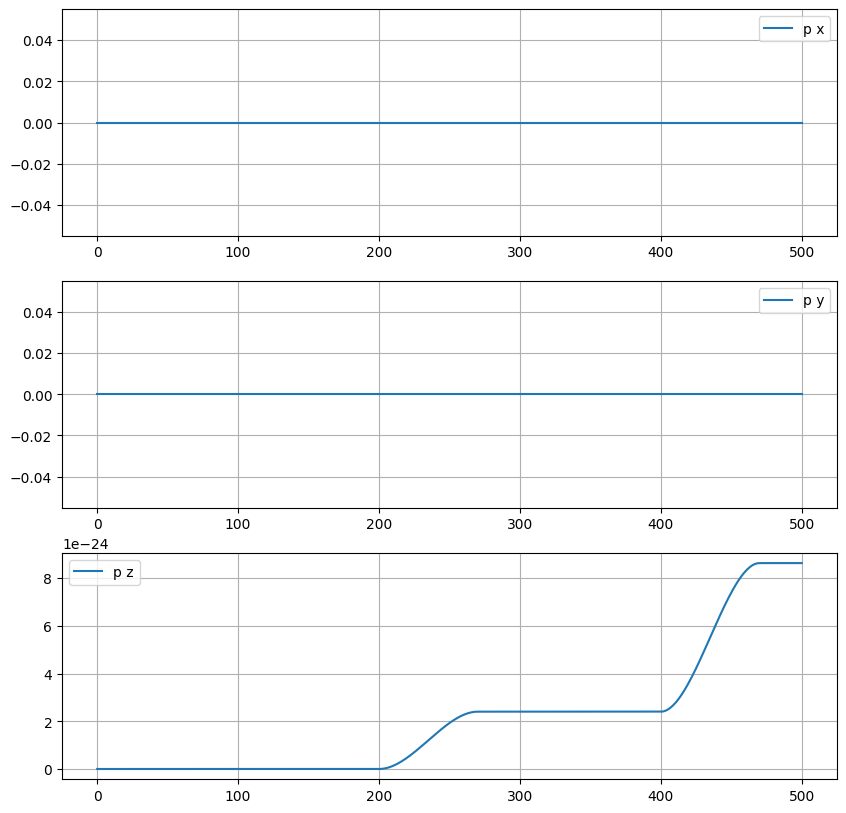

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(lfoot_ori_x,label="p x")
axes[1].plot(lfoot_ori_y,label="p y")
axes[2].plot(lfoot_ori_z,label="p z")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

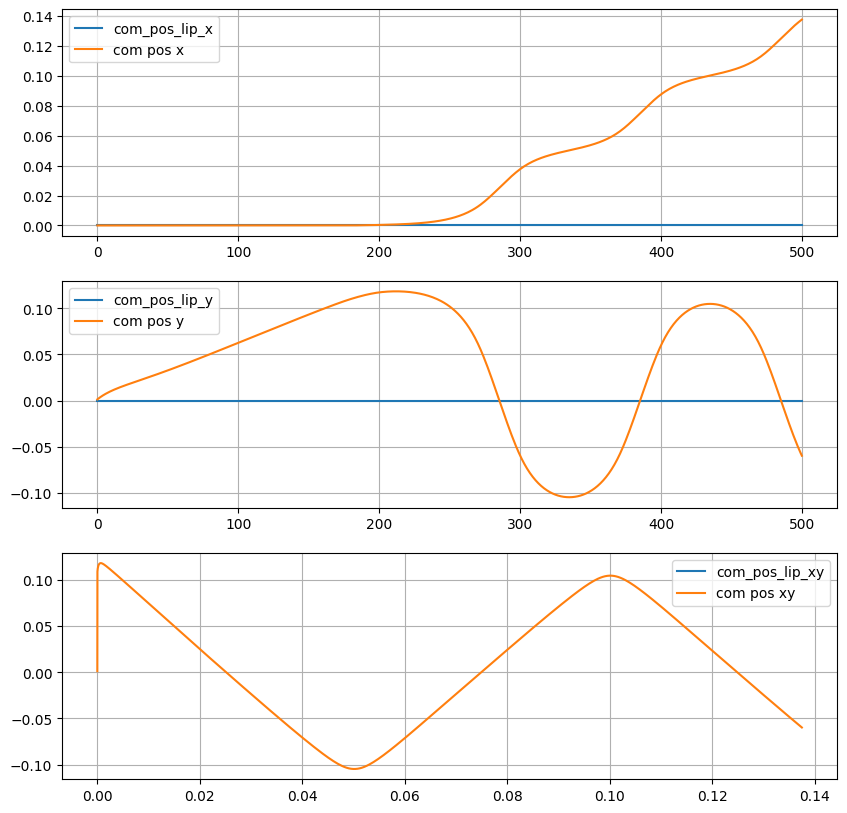

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(com_pos_lip_x,label="com_pos_lip_x")
axes[0].plot(com_pos_x,label="com pos x")
axes[1].plot(com_pos_lip_y,label="com_pos_lip_y")
axes[1].plot(com_pos_y,label="com pos y")
axes[2].plot(com_pos_lip_x,com_pos_lip_y,label="com_pos_lip_xy")
axes[2].plot(com_pos_x,com_pos_y,label="com pos xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

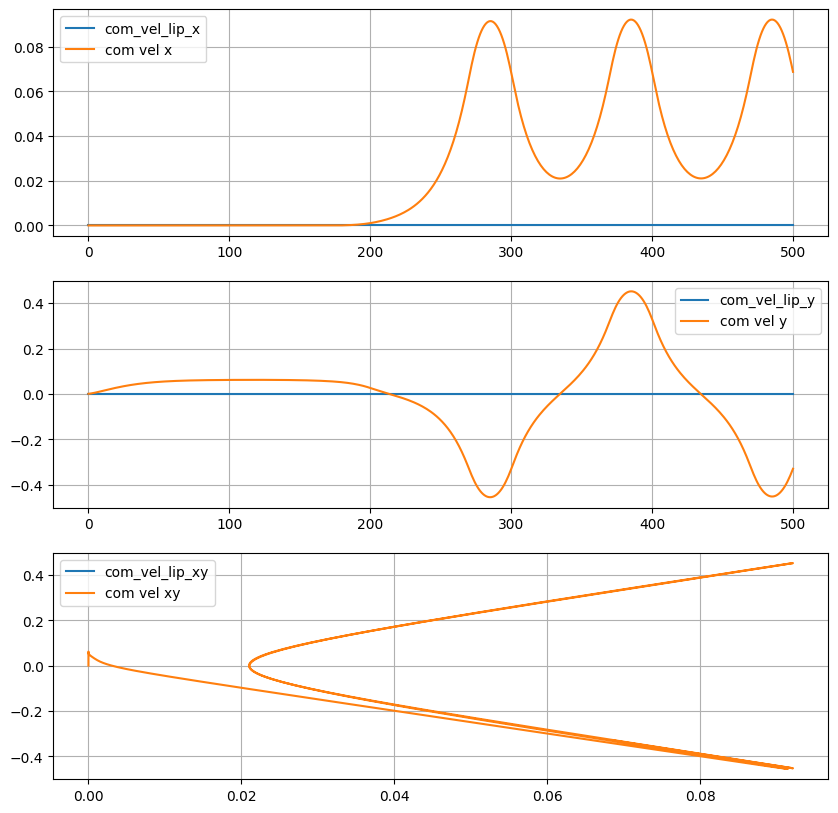

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(com_vel_lip_x,label="com_vel_lip_x")
axes[0].plot(com_vel_x,label="com vel x")
axes[1].plot(com_vel_lip_y,label="com_vel_lip_y")
axes[1].plot(com_vel_y,label="com vel y")
axes[2].plot(com_vel_lip_x,com_vel_lip_y,label="com_vel_lip_xy")
axes[2].plot(com_vel_x,com_vel_y,label="com vel xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

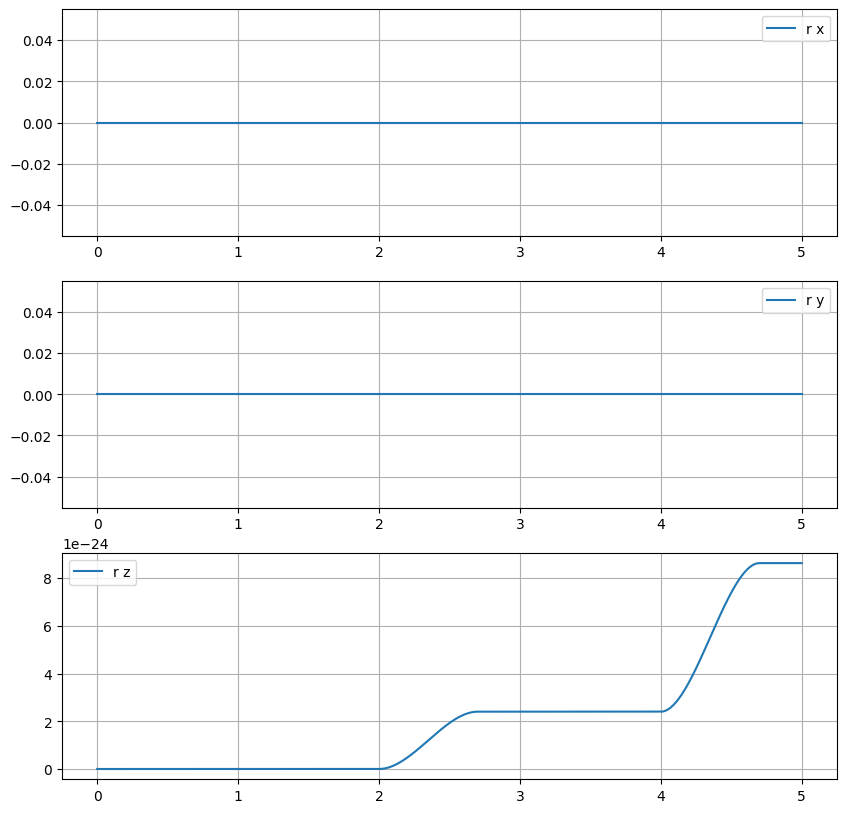

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(t,lfoot_ori_x,label="r x")
axes[1].plot(t,lfoot_ori_y,label="r y")
axes[2].plot(t,lfoot_ori_z,label="r z")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

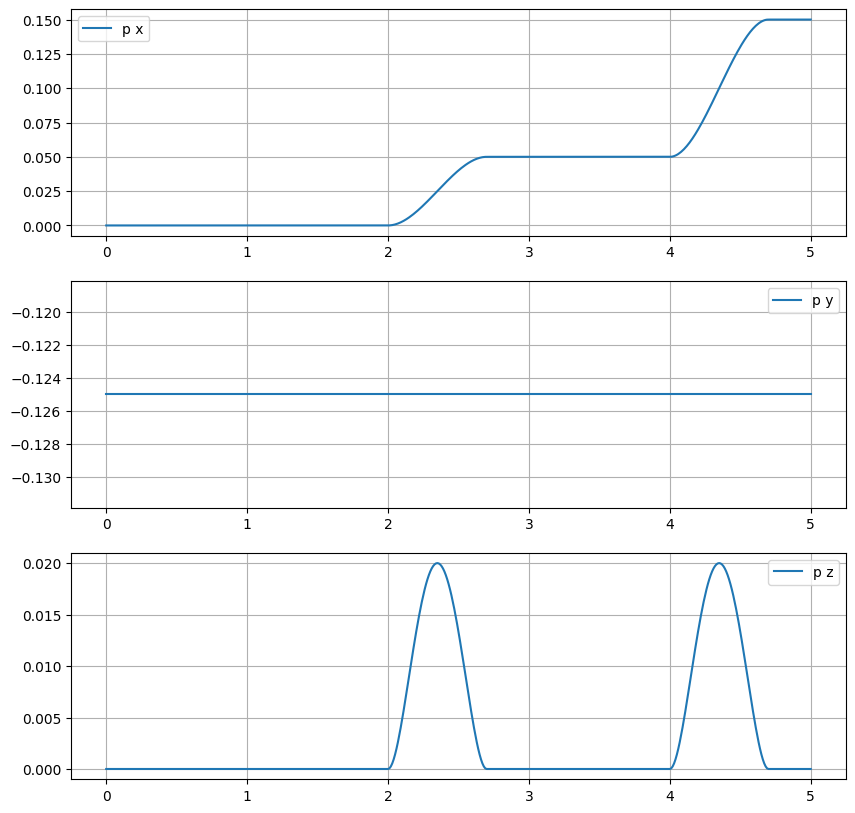

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(t,lfoot_pos_x,label="p x")
axes[1].plot(t,lfoot_pos_y,label="p y")
axes[2].plot(t,lfoot_pos_z,label="p z")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

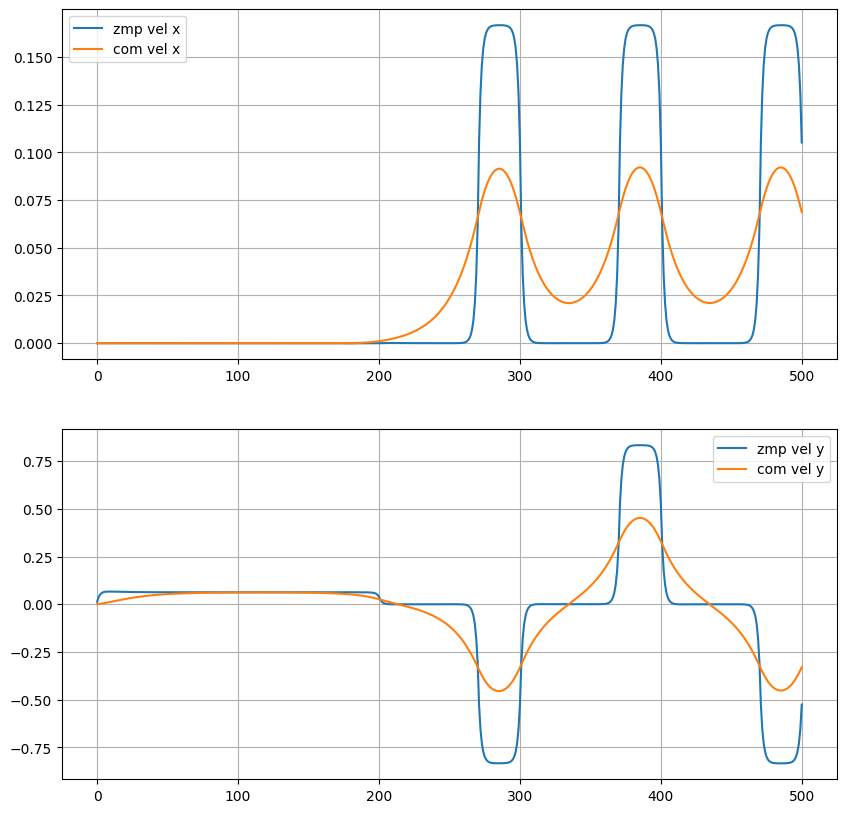

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))
axes[0].plot(zmp_vel_x,label="zmp vel x")
axes[1].plot(zmp_vel_y,label="zmp vel y")
axes[0].plot(com_vel_x,label="com vel x")
axes[1].plot(com_vel_y,label="com vel y")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

In [32]:
# --- Simulation Parameters ---
h_c = 0.3  # Height for HRP-4 [cite: 904]
dt = 0.02   # Sampling time [cite: 907]
T = 15     # Simulation duration
num_steps = int(T / dt)

# Initial State: CoM at origin, zero velocity, ZMP at origin [cite: 888]
init_state = [0.0, 0.0, zmp_vel_x[0]]
# time, trajectory = compute_lip_dynamics(T, dt, h_c, zmp_vel_input, init_state)
time, trajectory_x = compute_lip_dynamics(T, dt, h_c, zmp_vel_x, init_state)
plot_gait_results(time, trajectory_x)
init_state = [0.0, 0.0, 0.0]
time, trajectory_y = compute_lip_dynamics(T, dt, h_c, zmp_vel_y, init_state)
plot_gait_results(time, trajectory_y)

750
Initial State: [0.0, 0.0, np.float64(0.0)]


IndexError: index 501 is out of bounds for axis 0 with size 501

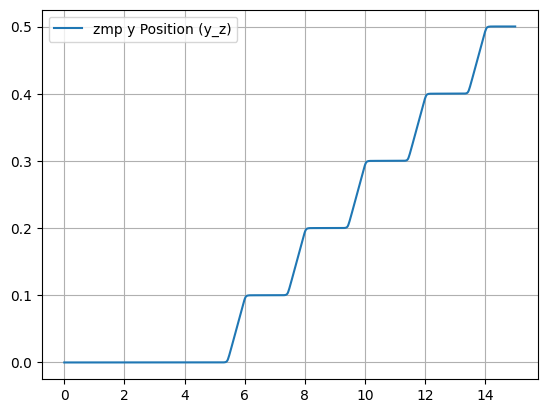

In [ ]:
plt.plot(time, trajectory_x[:,2], label='zmp y Position (y_z)')
plt.grid(True)
plt.legend()
plt.show()

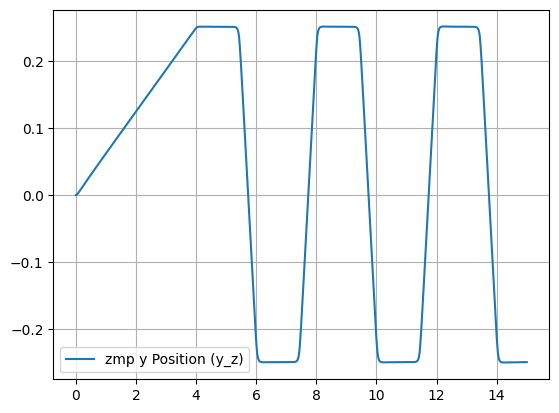

In [ ]:
plt.plot(time, trajectory_y[:,2], label='zmp y Position (y_z)')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
prog = MathematicalProgram()
ZMP_vel = prog.NewContinuousVariables(50,2,"ZMP_vel")

NameError: name 'MathematicalProgram' is not defined

In [ ]:
ZMP_vel[0,0]

Variable('ZMP_vel(0,0)', Continuous)

In [ ]:
i = 49
np.sum(ZMP_vel[:i+1,:], axis=0, keepdims=True) 

array([[<Expression "(ZMP_vel(0,0) + ZMP_vel(1,0) + ZMP_vel(2,0) + ZMP_vel(3,0) + ZMP_vel(4,0) + ZMP_vel(5,0) + ZMP_vel(6,0) + ZMP_vel(7,0) + ZMP_vel(8,0) + ZMP_vel(9,0) + ZMP_vel(10,0) + ZMP_vel(11,0) + ZMP_vel(12,0) + ZMP_vel(13,0) + ZMP_vel(14,0) + ZMP_vel(15,0) + ZMP_vel(16,0) + ZMP_vel(17,0) + ZMP_vel(18,0) + ZMP_vel(19,0) + ZMP_vel(20,0) + ZMP_vel(21,0) + ZMP_vel(22,0) + ZMP_vel(23,0) + ZMP_vel(24,0) + ZMP_vel(25,0) + ZMP_vel(26,0) + ZMP_vel(27,0) + ZMP_vel(28,0) + ZMP_vel(29,0) + ZMP_vel(30,0) + ZMP_vel(31,0) + ZMP_vel(32,0) + ZMP_vel(33,0) + ZMP_vel(34,0) + ZMP_vel(35,0) + ZMP_vel(36,0) + ZMP_vel(37,0) + ZMP_vel(38,0) + ZMP_vel(39,0) + ZMP_vel(40,0) + ZMP_vel(41,0) + ZMP_vel(42,0) + ZMP_vel(43,0) + ZMP_vel(44,0) + ZMP_vel(45,0) + ZMP_vel(46,0) + ZMP_vel(47,0) + ZMP_vel(48,0) + ZMP_vel(49,0))">,
        <Expression "(ZMP_vel(0,1) + ZMP_vel(1,1) + ZMP_vel(2,1) + ZMP_vel(3,1) + ZMP_vel(4,1) + ZMP_vel(5,1) + ZMP_vel(6,1) + ZMP_vel(7,1) + ZMP_vel(8,1) + ZMP_vel(9,1) + ZMP_vel(10,1) 

In [ ]:

class MPCParameters:
    def __init__(self, h_com=0.3,C=50,P=100):
        self.dt = 0.02
        self.h_com = h_com
        self.C = C
        self.P = P
        self.g = 9.81
        self.eta = np.sqrt(self.g/self.h_com)
        self.ss_ratio = 0.8
        self.ds_ratio = 1.0 - self.ss_ratio 
        self.max_ZMP_vel = 4.0

class RobotParameters:
    def __init__(self):
        self.foot_length = 0.2
        self.foot_width = 0.1
        self.l = 0.25
        # Kinematic admissible region (Rectangle dimensions)
        self.d_ax = 0.6        # Sagittal size
        self.d_ay = 0.2       # Coronal size

class ISMPC:
    def __init__(self, 
                 MPC_params:MPCParameters,
                 robot_params:RobotParameters):
        self.mpc_params = MPC_params
        self.robot_params = robot_params
        self.InitSolver()
        self.zmp_ant_vel = []
        self.initial_support_position = np.zeros(2)
    
    def InitSolver(self):
        self.prog = MathematicalProgram()
        self.ZMP_vel = self.prog.NewContinuousVariables(self.mpc_params.C,2,"ZMP_vel")    # decision variable for ZMP velocity
        self.prog.AddCost(np.sum(self.ZMP_vel**2))
        self.Tc_end_time = self.mpc_params.C * self.mpc_params.dt
        self.sampling_interval = 10.0
        self.ds_interval = 5.0
        # Precompute constants for stability constraints
        self.exp_constant = np.exp(-1.0*self.mpc_params.eta * self.mpc_params.dt)
        self.fraction_constant =  self.mpc_params.eta/(1.0 - self.exp_constant)
        self.sum_over_cntl_horizon_x = 0.0
        self.sum_over_cntl_horizon_y = 0.0
        # ZMP constrains variables
        half_length = self.robot_params.foot_length / 2
        half_width = self.robot_params.foot_width / 2
        lb = np.array([[-half_length, -half_width]])
        ub = np.array([[half_length, half_width]])
        self.zmp_bindings = []
        # Loop over control horizon
        for i in range(self.mpc_params.C):
            self.sum_over_cntl_horizon_x += (self.exp_constant**i)*self.ZMP_vel[i,0]
            self.sum_over_cntl_horizon_y += (self.exp_constant**i)*self.ZMP_vel[i,1]

            # ZMP constrains
            expr = self.mpc_params.dt*np.sum(self.ZMP_vel[:i+1], axis=0, keepdims=True) 
            # print(expr)
            binding = self.prog.AddLinearConstraint(expr, lb, ub)
            self.zmp_bindings.append(binding)
        # self._AddZMPVelocityConstraint(gamma=self.mpc_params.max_ZMP_vel)

    def GetSupportFoot(self, 
                       t, 
                       candidate_footsteps_x,
                       candidate_footsteps_y, 
                       footstep_orientations,
                       footstep_timings):
        ind = np.where(footstep_timings >= t)[0][0]
        return [candidate_footsteps_x[ind], candidate_footsteps_y[ind], footstep_orientations[ind]]

    def solve(self,
              t_relative,   
              candidate_footsteps_x,
              candidate_footsteps_y,
              footstep_orientations,
              footstep_timings,
              init_zmp_positions,
              curr_com_states:States,
              init_support_position=False):
        F_prime = np.where(np.array(footstep_timings) <= self.Tc_end_time)[0][-1] + 1
        self.mod_footsteps = self.prog.NewContinuousVariables(F_prime,2,"mod_footsteps")    # decision variable for modified footsteps
        self.prog.AddCost(np.sum((self.mod_footsteps[:,0] - np.array(candidate_footsteps_x[:F_prime]))**2 
                                 + (self.mod_footsteps[:,1] - np.array(candidate_footsteps_y[:F_prime]))**2))
        self.zmp_ant_pos = self.compute_zmp_ant_trajectory(footstep_timings=footstep_timings,
                                                                                    candidate_fs_x=candidate_footsteps_x,
                                                                                    candidate_fs_y=candidate_footsteps_y,
                                                                                    time_offset=t_relative)
        zmp_ant_vel = self.compute_zmp_vel_ant(zmp_ant_pos=self.zmp_ant_pos)
        self.zmp_ant_vel = zmp_ant_vel
        self._AddStabilityConstraint(com_states=curr_com_states,
                                     init_zmp_position=init_zmp_positions,
                                     zmp_ant_vel=zmp_ant_vel)
        # loop over the control horizon
        print(f"ds interval {self.ds_interval}")
        for i in range(self.mpc_params.C):
            # current_time_step = i
            # curr_time = i * self.mpc_params.dt + t_relative
            # curr_footstep = np.array([candidate_footsteps_x[0],
            #                           candidate_footsteps_y[0],
            #                           footstep_orientations[0]]) # x y theta
            # next_footstep = np.array([candidate_footsteps_x[1],
            #                           candidate_footsteps_y[1]])
            # print("="*50)
            # print(f"Current Time: {curr_time:.2f}")
            # if curr_time < footstep_timings[1]*self.mpc_params.ds_ratio:
            #     is_ds = True
            #     self.sampling_interval = int(footstep_timings[1]*self.mpc_params.ds_ratio/self.mpc_params.dt)
            # else:              
            #     is_ds = False
            # if init_support_position:
            #     self.initial_support_position = np.zeros(3)
            # else:
            #     self.initial_support_position = curr_footstep
            # self._AddZMPConstraint(curr_footstep=self.initial_support_position,
            #                        next_footstep=next_footstep,
            #                        init_zmp_position=init_zmp_positions,
            #                        is_ds=is_ds,
            #                        curr_time_step=current_time_step)

            curr_time = i * self.mpc_params.dt + t_relative
            
            # FIND WHICH FOOT WE ARE ON AT THIS FUTURE TIME
            # Find index 'j' such that timings[j] <= curr_time < timings[j+1]
            idx = np.where(np.array(footstep_timings) <= curr_time)[0][-1]
            
            # Logic for Double Support (Foot Changing)
            time_since_step_start = curr_time - footstep_timings[idx]
            T_ds = self.mpc_params.dt * 10 
            
            if idx > 0 and time_since_step_start < T_ds:
                alpha = time_since_step_start / T_ds
            else:
                alpha = 1.0 # Fully on the current 'idx' foot
            
            beta = 1.0 - alpha
            
            # IMPORTANT: Get footprint centers for this specific time
            # If these steps are within F_prime, use mod_footsteps variables!
            if idx < F_prime:
                # Use decision variables so the footprints can move to satisfy stability
                foot_now = self.mod_footsteps[idx]
                foot_prev = self.mod_footsteps[idx-1] if idx > 0 else self.initial_support_position
            else:
                # Use constants for footsteps beyond the modification horizon
                foot_now = np.array([candidate_footsteps_x[idx], candidate_footsteps_y[idx]])
                foot_prev = np.array([candidate_footsteps_x[idx-1], candidate_footsteps_y[idx-1]])

            moving_origin = beta * foot_prev + alpha * foot_now
            
            # Update the Binding
            # If rotation is 0, R_T is Identity. 
            # Ensure _UpdateZMPBinding matches your 'expr' in InitSolver
            self._UpdateZMPBinding(i, np.eye(2), moving_origin, init_zmp_positions)
        
        self.prog.SetInitialGuess(self.ZMP_vel, np.zeros((self.mpc_params.C,2)))
        self.prog.SetInitialGuess(self.mod_footsteps, np.array([candidate_footsteps_x[:F_prime], candidate_footsteps_y[:F_prime]]).T)
        result = Solve(self.prog)
        if result.is_success():
            print("Optimal solution found!")
            optimal_ZMP_vel = result.GetSolution(self.ZMP_vel)
            optimal_mod_footsteps = result.GetSolution(self.mod_footsteps)
            return optimal_ZMP_vel, optimal_mod_footsteps
        else:
            print("No optimal solution found.")
            return None, None
        
    def _UpdateZMPBinding(self, i, R_T, moving_origin, init_zmp):
        binding = self.zmp_bindings[i]
        evaluator:LinearConstraint = binding.evaluator()
        
        # The expression is: R^T * ( sum(vel*dt) - moving_origin + init_zmp )
        # To update lb <= Ax <= ub, we move constants to the bounds:
        # lb + R^T*(moving_origin - init_zmp) <= R^T * sum(vel*dt) <= ub + R^T*(moving_origin - init_zmp)
        # R*[lb + R^T*(moving_origin - init_zmp)]/dt <= sum(vel) <= R*[ub + R^T*(moving_origin - init_zmp)]/dt
        
        offset = R_T @ (moving_origin - init_zmp)
        half_lb = np.array([[-self.robot_params.foot_length/2, -self.robot_params.foot_width/2]])
        half_ub = np.array([[self.robot_params.foot_length/2, self.robot_params.foot_width/2]])
        # print((half_lb + offset).T.shape)
        # print(R_T.T.shape)
        # New Bounds 
        new_lb = (R_T.T @ (half_lb + offset).T)
        new_ub = (R_T.T @ (half_ub + offset).T)
        print("R_T", R_T)
        print(f"lb {((half_lb + offset).T)}")
        print(f"ub {(half_ub + offset).T}")
        evaluator.set_bounds(new_lb, new_ub)
        print("curr ub",evaluator.upper_bound())
        print("curr lb",evaluator.lower_bound())

    def _AddZMPConstraint(self, 
                        curr_footstep, 
                        next_footstep,
                        init_zmp_position,
                        is_ds,
                        curr_time_step):
        W_R_foot = RotationMatrix.MakeZRotation(curr_footstep[2]).matrix()

        if is_ds:
            if self.ds_interval < self.sampling_interval:
                self.ds_interval += 1.0
            alpha = self.ds_interval / self.sampling_interval
            beta = 1.0 - alpha
            # print(f"DS Phase: alpha={alpha:.2f}, beta={beta:.2f}, ds_interval={self.ds_interval:.2f}")
            # print(f"curr footstep : {curr_footstep[0],curr_footstep[1]}, next footstep : {next_footstep[0],next_footstep[1]}")

        else:
            # print("SS Phase")
            alpha = 1.0
            beta = 0.0
            self.ds_interval = 0.0
        # print("init_zmp_position",init_zmp_position)
        print(f"moving support origin : {beta*curr_footstep[0] + alpha*next_footstep[0], beta*curr_footstep[1] + alpha*next_footstep[1]}")
        print(f"support area: {beta*curr_footstep[0] + alpha*next_footstep[0] + self.robot_params.foot_length/2}, {beta*curr_footstep[1] + alpha*next_footstep[1] + self.robot_params.foot_width/2}")
        term_x = ((np.sum(self.ZMP_vel[:curr_time_step,0]) * self.mpc_params.dt) 
                            - beta*curr_footstep[0] 
                            - alpha*next_footstep[0] 
                            + init_zmp_position[0])
        term_y = ((np.sum(self.ZMP_vel[:curr_time_step,1]) * self.mpc_params.dt) 
                            - beta*curr_footstep[1] 
                            - alpha*next_footstep[1] 
                            + init_zmp_position[1])
        
        # This is an array of Expressions
        lhs = W_R_foot[:2,:2].T @ np.array([term_x, term_y])
        
        # Define bounds
        half_width = self.robot_params.foot_width / 2
        half_length = self.robot_params.foot_length / 2
        print(f"constant term x {(half_width+ beta*curr_footstep[0] + alpha*next_footstep[0] - init_zmp_position[0])}")
        print(f"constant term y {(half_length+ beta*curr_footstep[1] + alpha*next_footstep[1] - init_zmp_position[1])}")
        upper_bound = np.array([half_length, half_width])
        lower_bound = -upper_bound

        # FIX: Pass the expression and bounds separately
        # Format: AddConstraint(expression, lower_bound, upper_bound)
        # self.prog.AddConstraint(lhs, lower_bound, upper_bound)
        if curr_time_step >= 1:
            print(lhs)
            print("ub half width", half_width)
            self.prog.AddLinearConstraint(lhs, lower_bound, upper_bound)

    def _AddZMPVelocityConstraint(self, gamma):
        """
        Adds the constraint |zmp_vel| <= gamma for both x and y directions.
        Based on Section IV-A of the 2020 paper.
        """
        # Define the lower and upper bounds for the entire control horizon
        # self.ZMP_vel is a (C, 2) array of decision variables
        lower_bound = -gamma * np.ones((self.mpc_params.C, 2))
        upper_bound = gamma * np.ones((self.mpc_params.C, 2))
        
        # Add the bounding box constraint to the MathematicalProgram
        self.prog.AddBoundingBoxConstraint(lower_bound, upper_bound, self.ZMP_vel)

    def _AddKinematicsConstraint(self,):
        pass  

    def _AddStabilityConstraint(self,
                                com_states, 
                                init_zmp_position, 
                                zmp_ant_vel):
        """
        Adds the linear stability constraint (Eq 18 from 2020 paper).
        Ensures CoM boundedness w.r.t ZMP.
        """
        # 1. Calculate current unstable modal coordinates (DCM/Capture Point)
        # Using your existing CalcModalCoordinates method
        x_u, y_u = self.CalcModalCoordinates(com_states)
        # print(x_u,y_u)
        # 2. Left-hand side: Sum of discounted ZMP velocities over control horizon
        # Precomputed in InitSolver: self.sum_over_cntl_horizon_x/y
        
        # 3. Right-hand side (RHS) constant term:
        # RHS = -tail_sum + [eta / (1 - exp(-eta*dt))] * (x_u - x_z)
        # For a simple 'Truncated Tail', the tail_sum is 0 [cite: 828]
        sum_ant_tail_x = 0.0
        sum_ant_tail_y = 0.0
        for i in range(self.mpc_params.C,self.mpc_params.P):
            sum_ant_tail_x += (self.exp_constant**i) * zmp_ant_vel[i-self.mpc_params.C,0]
            sum_ant_tail_y += (self.exp_constant**i) * zmp_ant_vel[i-self.mpc_params.C,1]
            # print(i)
        rhs_const_x = self.fraction_constant * (x_u - init_zmp_position[0]) - sum_ant_tail_x
        rhs_const_y = self.fraction_constant * (y_u - init_zmp_position[1]) - sum_ant_tail_y
        
        # 4. Add the equality constraints
        # self.prog.AddLinearConstraint(self.sum_over_cntl_horizon_x-rhs_const_x,-10,10)
        # self.prog.AddLinearConstraint(self.sum_over_cntl_horizon_y-rhs_const_y,-10,10)
        self.prog.AddLinearEqualityConstraint(self.sum_over_cntl_horizon_x, rhs_const_x)
        self.prog.AddLinearEqualityConstraint(self.sum_over_cntl_horizon_y, rhs_const_y)

    def compute_zmp_ant_trajectory(self, footstep_timings, candidate_fs_x, candidate_fs_y,time_offset=0.0):
        """
        Computes future ZMP positions from Tc to Tp with interpolation during 
        double support phases to match the moving ZMP constraint.
        [cite: 1641, 1643, 1645]
        """
        num_tail_samples = self.mpc_params.P - self.mpc_params.C
        # print(f"num tail sample {num_tail_samples}")
        zmp_ant_pos = np.zeros((num_tail_samples, 2))
        
        # Define double support duration based on your robot's parameters
        # The paper often uses a 60%-40% or fixed ratio for SS/DS [cite: 1226, 1669]
        T_ds = self.mpc_params.dt * 10  # Example: 10 samples for transition [cite: 1642]

        for i in range(num_tail_samples):
            t_global = (self.mpc_params.C + i) * self.mpc_params.dt + time_offset
            # print(f"time {t_global} s")
            # 1. Find the current step index
            idx = 0
            for j in range(len(footstep_timings) - 1):
                if footstep_timings[j] <= t_global < footstep_timings[j+1]:
                    idx = j
                    break
            else:
                idx = len(footstep_timings) - 1

            # 2. Detect if we are in the "Foot Changing" (Double Support) window
            # Double support happens at the start of the new step interval [cite: 1643]
            time_since_step_start = t_global - footstep_timings[idx]
            curr_idx = idx
            next_idx = idx + 1
            # if idx == (len(footstep_timings)-1):
            #     next_idx = curr_idx
            if idx > 0 and time_since_step_start < T_ds:
                # INTERPOLATION PHASE (Double Support) [cite: 732, 1646]
                # alpha goes from 0 to 1 over the duration of T_ds
                alpha = time_since_step_start / T_ds
                beta = 1.0 - alpha

                # ZMP = (1-alpha)*prev_foot + alpha*curr_foot [cite: 1646]
                zmp_ant_pos[i, 0] = beta * candidate_fs_x[curr_idx] + alpha * candidate_fs_x[next_idx]
                zmp_ant_pos[i, 1] = beta * candidate_fs_y[curr_idx] + alpha * candidate_fs_y[next_idx]
            else:
                # STABLE PHASE (Single Support) [cite: 1641]
                zmp_ant_pos[i, 0] = candidate_fs_x[next_idx]
                zmp_ant_pos[i, 1] = candidate_fs_y[next_idx]
                    
        return zmp_ant_pos
    
    def compute_zmp_vel_ant(self, zmp_ant_pos):
        # Compute velocity samples via discrete differentiation
        # Eq 5: x_z(t) = x_z^j + (t - t_j) * x_dot_z^j
        zmp_vel_ant = np.diff(zmp_ant_pos, axis=0) / self.mpc_params.dt
        
        # Append a zero at the end to match the required vector length
        zmp_vel_ant = np.vstack([zmp_vel_ant, [0, 0]])
        return zmp_vel_ant
    
    def CalcModalCoordinates(self, com_states:States):
        x_c = com_states.position[0]
        y_c = com_states.position[1]
        x_dot_c = com_states.linear_velocity[0]
        y_dot_c = com_states.linear_velocity[1]
        # Calc unstable mode
        x_u = x_c + (1/self.mpc_params.eta) * x_dot_c
        y_u = y_c + (1/self.mpc_params.eta) * y_dot_c
        return x_u, y_u
    
    def CalcMinPreviewHorizon(self):
        """
        Computes the minimum preview horizon required for recursive feasibility.
        Based on Proposition 5 and Equation 28 (Scianca et al. 2020).
        
        Args:
            eta: LIP parameter sqrt(g/h_c) 
            Tc: Control horizon duration in seconds 
            v_z_max: Max ZMP velocity (gamma) 
            d_zx: ZMP admissible region width (foot width) 
            
        Returns:
            min_Tp: Minimum preview horizon (s) 
        """
        # Inside the log: (2 * v_z_max) / (eta * d_zx)
        eta = self.mpc_params.eta
        Tc = self.mpc_params.C * self.mpc_params.dt
        v_z_max = self.mpc_params.max_ZMP_vel
        d_zx = self.robot_params.foot_length
        log_argument = (2 * v_z_max) / (eta * d_zx)
        
        # Calculate additional preview needed 
        additional_preview = (1 / eta) * np.log(log_argument)
        
        # Total required Tp 
        min_Tp = Tc + additional_preview
        
        return min_Tp



In [ ]:
# simulation_time = 3.0 # s
# curr_sim_time = 0.0
# dt = 0.02
# ts = 1.0
# Tp = 2.0
# t_relative = 0.0
# ds_ratio = 0.2
# planner = FootstepPlanner()
# prev_foot_plan = None
# side = 'left'
# phase = [] # 0 for single stance, 1 for double stance
# timestamp = []
# initial_pose = [0.0, 0.125, 0.0]
# def VRefCommand1(t):
#     if t < 1.0:
#         return [0.0, 0.0, 0.0]
#     else:
#         return [0.1, 0.0, 0.0]
    
# def VRefCommand2(t):
#     return [0.1, 0.0, 0.0]

# mpc_params = MPCParameters()
# mpc_params.C = 50
# robot_params = RobotParameters()
# robot_params.foot_length = 0.05
# robot_params.foot_width = 0.05
# ismpc = ISMPC(MPC_params=mpc_params,
#               robot_params=robot_params)

# # foot_planned = planner.PlanFootsteps(initial_pose, VRefCommand, Tp+1.0, side)
# ds_interval = 5.0
# LIP_states_x_m1 = np.zeros(3)
# LIP_states_y_m1 = np.zeros(3)
# LIP_states_x    = np.zeros(3)
# LIP_states_y    = np.zeros(3)
# init_zmp_positions      = [0.0, 0.0]
# curr_com_states = States(name="com_states")
# curr_com_states.position = np.array([0.0,0.0,0.3])
# init_flag = True
# while curr_sim_time < simulation_time:
#     if init_flag:
#         foot_planned = planner.PlanFootsteps(initial_pose, VRefCommand1, Tp+1.0, side)
#     else:
#         side = prev_foot_plan[0]['side']
#         foot_planned = planner.PlanFootsteps(initial_pose, VRefCommand2, Tp+1.0, side)
#     print("="*50)
#     print(f"Global time {curr_sim_time} s")
#     print(f"Relative time {t_relative} s")
#     print(f"ds interval {ds_interval}")
#     if t_relative < ts * ds_ratio:
#         phase.append(1) # Double Stance
#         ismpc.ds_interval = ds_interval
#         ds_interval += 1.0
#     else:
#         phase.append(0) # Single Stance
#         ds_interval = 0.0
#         ismpc.ds_interval = ds_interval
#     print(f"planner.candidate_footsteps.X {planner.candidate_footsteps.X}")
#     print(f"planner.candidate_footsteps.Y {planner.candidate_footsteps.Y}")
#     print(f"planner.candidate_footsteps.ori {planner.candidate_footsteps.orientation}")
#     print(f"planner.candidate_footsteps.timing {planner.candidate_footsteps.timing}")
#     print(f"initial zmp positon {init_zmp_positions}")
#     optimal_ZMP_vel, optimal_mod_footsteps = ismpc.solve(t_relative=t_relative, 
#                                                         candidate_footsteps_x=planner.candidate_footsteps.X,     
#                                                         candidate_footsteps_y=planner.candidate_footsteps.Y,
#                                                         footstep_orientations=planner.candidate_footsteps.orientation,
#                                                         footstep_timings=planner.candidate_footsteps.timing,
#                                                         init_zmp_positions=init_zmp_positions,
#                                                         curr_com_states=curr_com_states)  
    
#     LIP_states_x  = CalcSigleStepLIP(dt=0.02,
#                                      h_c=0.3,
#                                      zmp_vel_input=optimal_ZMP_vel[0,0],
#                                      initial_state=LIP_states_x_m1
#                                     )
#     LIP_states_x_m1 = LIP_states_x
#     LIP_states_y  = CalcSigleStepLIP(dt=0.02,
#                                      h_c=0.3,
#                                      zmp_vel_input=optimal_ZMP_vel[0,1],
#                                      initial_state=LIP_states_y_m1
#                                     )
#     LIP_states_y_m1 = LIP_states_y 
#     print(f"LIP states {LIP_states_x}")
#     curr_com_states.position[0] = LIP_states_x[0]
#     curr_com_states.position[1] = LIP_states_y[0] 
#     curr_com_states.linear_velocity[0] = LIP_states_x[1]
#     curr_com_states.linear_velocity[1] = LIP_states_y[1]
#     init_zmp_positions[0] = LIP_states_x[2]
#     init_zmp_positions[1] = LIP_states_y[2]
#     print(f"Optimal ZMP velocity {optimal_ZMP_vel[0,:]}")
#     print(optimal_ZMP_vel[0,0])
#     print(f"CoM position {curr_com_states.position}")

#     if t_relative < ts:
#         t_relative += dt
#     else:
#         # planner.PlotFootsteps(foot_planned, initial_pose, VRefCommand, idx_offset)
#         print("NEW FOOTPLAN")
#         init_flag = 0
#         idx_offset += 1
#         t_relative = 0.0
#         prev_foot_plan = foot_planned
#         initial_pose = [prev_foot_plan[0]['x'], prev_foot_plan[0]['y'], prev_foot_plan[0]['theta']] 
#         side = prev_foot_plan[0]['side']


#     curr_sim_time += dt

In [ ]:
# mpc_params = MPCParameters()
# mpc_params.C = 50
# robot_params = RobotParameters()
# robot_params.foot_length = 0.05
# robot_params.foot_width = 0.05
# ismpc = ISMPC(MPC_params=mpc_params,
#               robot_params=robot_params)
# curr_time = 0.0
# candidtate_footsteps_x  = [0.0, 0.0, 0.1, 0.2]
# candidate_footsteps_y   = [0.125, -0.125, 0.125, -0.125]
# footstep_orientations   = [0.0, 0.0, 0.0,0.0]
# footstep_timings        = [0.0, 1.0, 2.0,3.0]
# init_zmp_positions      = [0.0, -0.0]
# curr_com_states = States(name="com_states")
# curr_com_states.position = np.array([0.0,0.0,0.3])
# ismpc.ds_interval = 0.0
# optimal_ZMP_vel, optimal_mod_footsteps = ismpc.solve(t_relative=curr_time, 
#                                                      candidate_footsteps_x=candidtate_footsteps_x,     
#                                                      candidate_footsteps_y=candidate_footsteps_y,
#                                                      footstep_orientations=footstep_orientations,
#                                                      footstep_timings=footstep_timings,
#                                                      init_zmp_positions=init_zmp_positions,
#                                                      curr_com_states=curr_com_states,
#                                                      init_support_position=1)   

In [ ]:
mpc_params = MPCParameters()
mpc_params.C = 200
mpc_params.P = 200
robot_params = RobotParameters()
robot_params.foot_length = 0.05
robot_params.foot_width = 0.05
ismpc = ISMPC(MPC_params=mpc_params,
              robot_params=robot_params)
curr_time = 0.0
candidtate_footsteps_x  = [0.0, 0.0, 0.1, 0.2]
candidate_footsteps_y   = [0.125, -0.125, 0.125, -0.125]
footstep_orientations   = [0.0, 0.0, 0.0,0.0]
footstep_timings        = [0.0, 1.0, 2.0,3.0]
init_zmp_positions      = [0.0, -0.0]
curr_com_states = States(name="com_states")
curr_com_states.position = np.array([0.0,0.0,0.3])
ismpc.ds_interval = 0.0
# optimal_ZMP_vel, optimal_mod_footsteps = ismpc.solve(t_relative=curr_time, 
#                                                      candidate_footsteps_x=candidtate_footsteps_x,     
#                                                      candidate_footsteps_y=candidate_footsteps_y,
#                                                      footstep_orientations=footstep_orientations,
#                                                      footstep_timings=footstep_timings,
#                                                      init_zmp_positions=init_zmp_positions,
#                                                      curr_com_states=curr_com_states,
#                                                      init_support_position=1)   

In [ ]:
plt.plot(optimal_ZMP_vel[:,0],label="zmp xd")
plt.plot(optimal_ZMP_vel[:,1],label="zmp yd")
plt.legend()
plt.grid()
plt.show()

NameError: name 'optimal_ZMP_vel' is not defined

Initial State: [0.0, 0.0, 0.0]


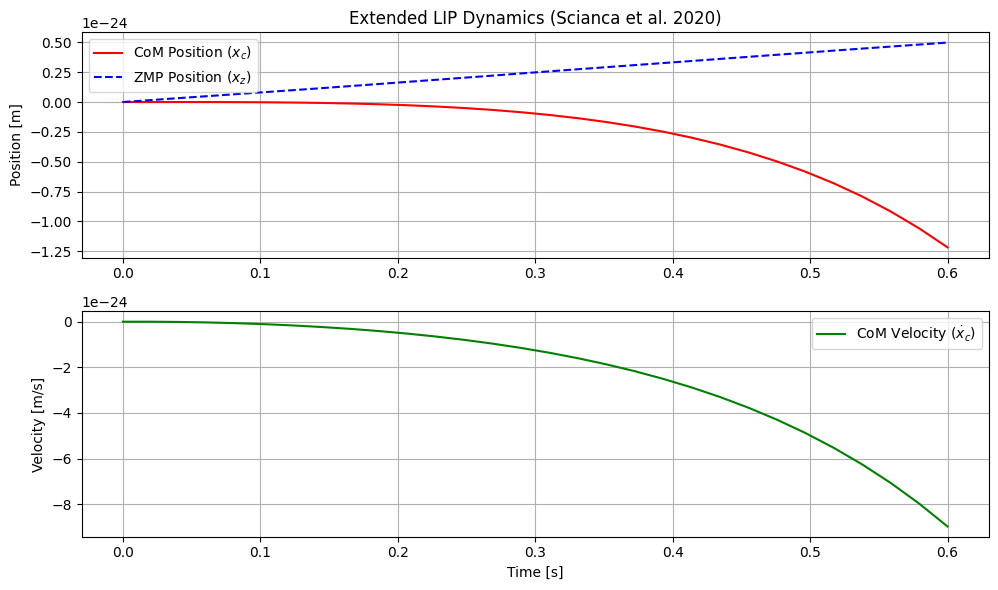

In [ ]:
# --- Simulation Parameters ---
h_c = 0.3  # Height for HRP-4 [cite: 904]
dt = 0.02   # Sampling time [cite: 907]
T = 0.6     # Simulation duration
num_steps = int(T / dt)

# Example input: Periodic ZMP velocity to simulate a simple step
# (In the real IS-MPC, this is solved via QP) [cite: 890]
zmp_vel_input = 0.5 * np.sin(2 * np.pi * np.linspace(0, T, num_steps))

# Initial State: CoM at origin, zero velocity, ZMP at origin [cite: 888]
init_state = [0.0, 0.0, 0.0]
# time, trajectory = compute_lip_dynamics(T, dt, h_c, zmp_vel_input, init_state)
time, trajectory_x = compute_lip_dynamics(T, dt, h_c, optimal_ZMP_vel[:,0], init_state)
plot_gait_results(time, trajectory_x)

Initial State: [0.0, 0.0, 0.0]


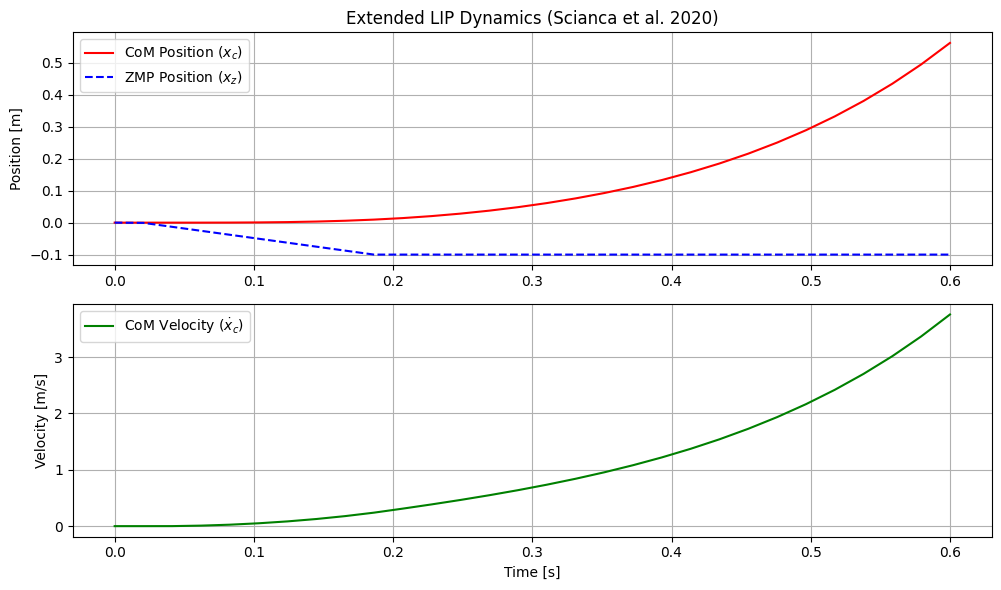

In [ ]:
init_state = [0.0, 0.0, 0.0]
# time, trajectory = compute_lip_dynamics(T, dt, h_c, zmp_vel_input, init_state)
time, trajectory_y = compute_lip_dynamics(T, dt, h_c, optimal_ZMP_vel[:,1], init_state)
plot_gait_results(time, trajectory_y)

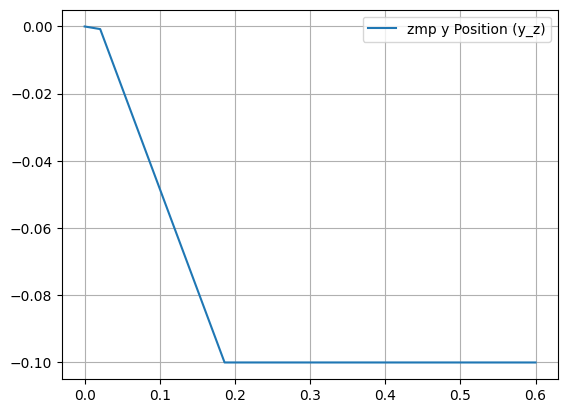

In [ ]:
plt.plot(time, trajectory_y[:,2], label='zmp y Position (y_z)')
plt.grid(True)
plt.legend()
plt.show()

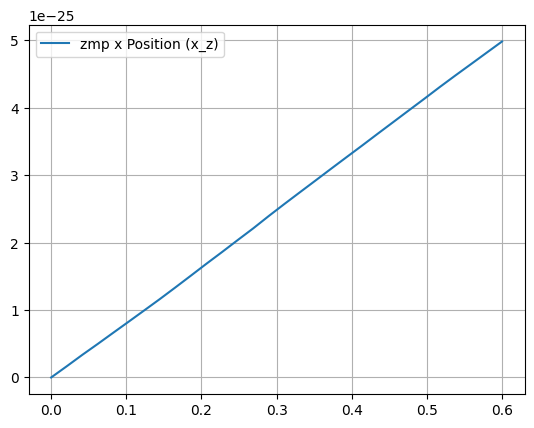

In [ ]:
plt.plot(time, trajectory_x[:,2], label='zmp x Position (x_z)')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
def PlotFootsteps(trajectory_x,trajectory_y,steps, initial_pose, v_ref_func=None, label_idx_offset=0):
    """
    Visualizes the plan.
    """
    if v_ref_func:
        fig, axes = plt.subplots(2, 1, figsize=(10, 10), 
                                    gridspec_kw={'height_ratios': [2, 1]})
        ax_map, ax_vel = axes[0], axes[1]
    else:
        fig, ax_map = plt.subplots(figsize=(10, 6))
        ax_vel = None

    ax_map.set_title("Footstep Planner Output")
    ax_map.set_xlabel("X (m)")
    ax_map.set_ylabel("Y (m)")
    ax_map.axis('equal')
    ax_map.grid(True, alpha=0.3)

    def DrawFoot(ax, x, y, theta, side, label_idx=None):
        width = 0.05  
        height = 0.05 
        color = 'blue' if side == 'left' else 'red'
        
        rect = Rectangle((-width/2, -height/2), width, height, 
                            color=color, alpha=0.5)
        
        t = transforms.Affine2D().rotate(theta).translate(x, y) + ax.transData
        rect.set_transform(t)
        ax.add_patch(rect)
        
        ax.arrow(x, y, 0.15*np.cos(theta), 0.15*np.sin(theta),
                    head_width=0.03, color='k', alpha=0.7)
        
        if label_idx is not None:
            ax.text(x, y, str(label_idx), color='white', 
                    ha='center', va='center', fontweight='bold')

    # Draw Initial
    if steps:
        first_step_side = steps[0]['side']
        init_side = 'right' if first_step_side == 'left' else 'left'
    else:
        init_side = 'right'
        
    DrawFoot(ax_map, initial_pose[0], initial_pose[1], initial_pose[2], 
                init_side, label_idx = 0+label_idx_offset)

    # Draw Steps
    for s in steps:
        DrawFoot(ax_map, s['x'], s['y'], s['theta'], s['side'], 
                    label_idx=s['index']+label_idx_offset)

    # Draw Path
    xs = [initial_pose[0]] + [s['x'] for s in steps]
    ys = [initial_pose[1]] + [s['y'] for s in steps]
    ax_map.plot(xs, ys, 'k--', alpha=0.3, marker='o', markersize=3)
    ax_map.plot(trajectory_x, trajectory_y, label='ZMP Trajectory')
    # Velocity Plot
    if ax_vel and v_ref_func and steps:
        t_end = steps[-1]['t_end'] + 0.5
        ts = np.linspace(0, t_end, 200)
        v_data = np.array([v_ref_func(t) for t in ts])
        
        ax_vel.set_title("Reference Velocity Input")
        ax_vel.plot(ts, v_data[:, 0], label='$v_x$')
        ax_vel.plot(ts, v_data[:, 1], label='$v_y$')
        ax_vel.plot(ts, v_data[:, 2], label='$\omega$')
        ax_vel.set_xlabel("Time (s)")
        ax_vel.legend()
        ax_vel.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
planner = FootstepPlanner()

# Reference Velocity Function
def VRefCommand(t):
    if t < 2.0:
        return [0.0, 0.0, 0.0]
    elif t < 5.0:
        return [0.1, 0.0, 0.0] 
    else:
        return [0.01, 0.0, 0.0]
        
initial_pose = [0.0, 0.125, 0.0]

# Generate Plan
plan = planner.PlanFootsteps(initial_pose, VRefCommand, 2.0, 'left')
print(len(plan))
# Visualize
# planner.PlotFootsteps(plan, initial_pose, VRefCommand)

2


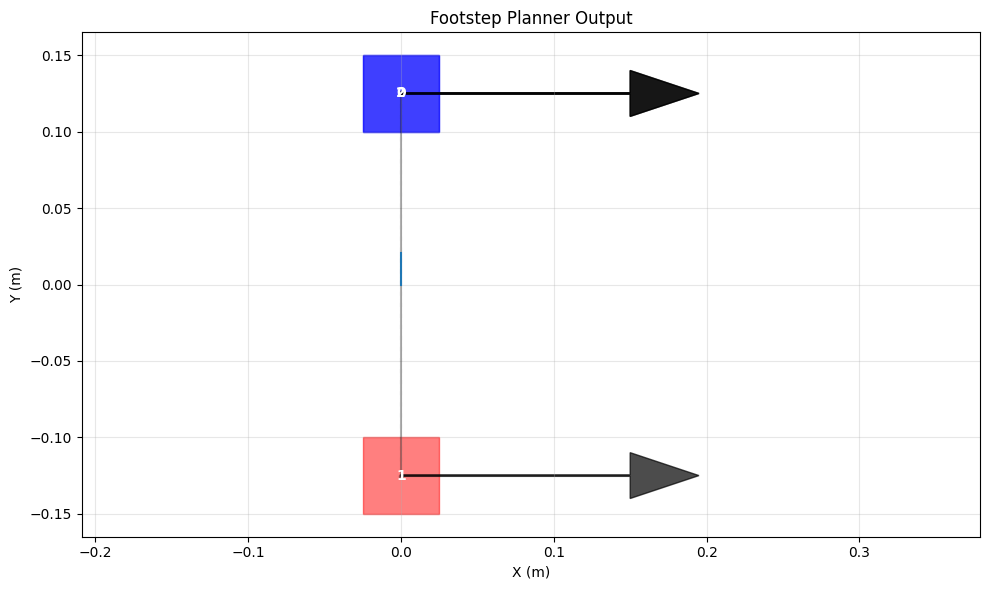

In [ ]:
PlotFootsteps(trajectory_x[:12,0], trajectory_y[:12,0], plan, initial_pose)

In [ ]:
trajectory_x[:,2]

array([0.00000000e+00, 1.65650954e-26, 3.34842157e-26, 4.97776992e-26,
       6.64371612e-26, 8.29932436e-26, 9.96748725e-26, 1.16444011e-25,
       1.33716563e-25, 1.51235757e-25, 1.68894924e-25, 1.86164708e-25,
       2.03787673e-25, 2.21191968e-25, 2.39496614e-25, 2.57260161e-25,
       2.74675823e-25, 2.92019460e-25, 3.09459525e-25, 3.26743539e-25,
       3.43933728e-25, 3.61401917e-25, 3.78696887e-25, 3.96026753e-25,
       4.13288665e-25, 4.30820883e-25, 4.47885380e-25, 4.64650180e-25,
       4.81492616e-25, 4.98271721e-25])

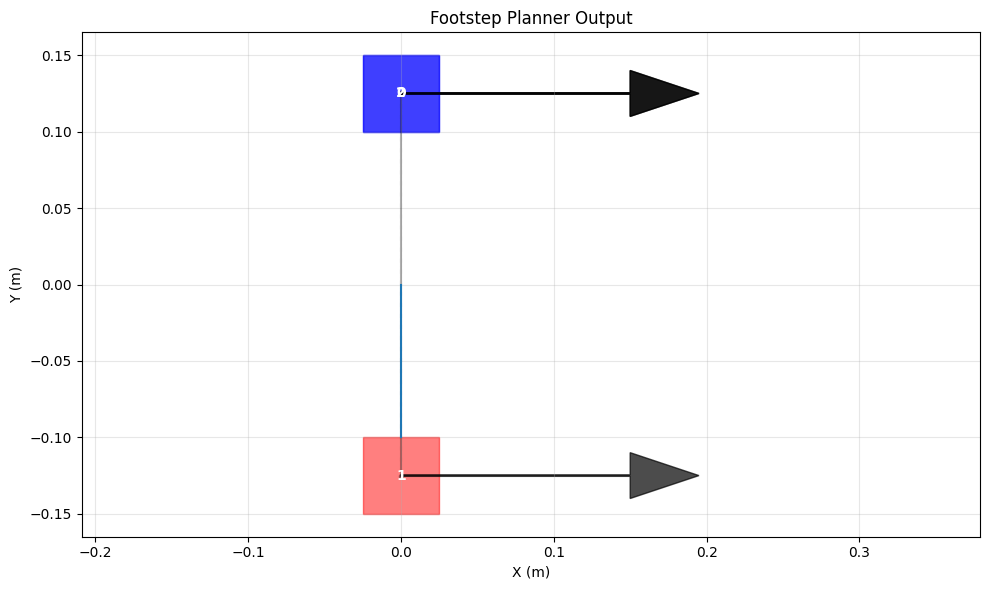

In [ ]:
PlotFootsteps(trajectory_x[:,2], trajectory_y[:,2], plan, initial_pose)

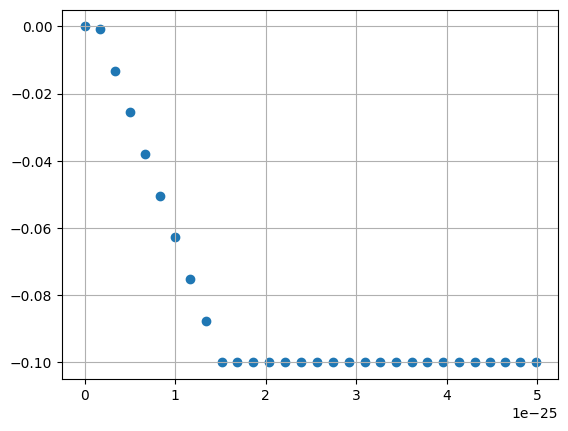

In [ ]:
plt.scatter(trajectory_x[:,2], trajectory_y[:,2], label='ZMP Trajectory (x_z vs y_z)')
plt.grid(True)
plt.show()

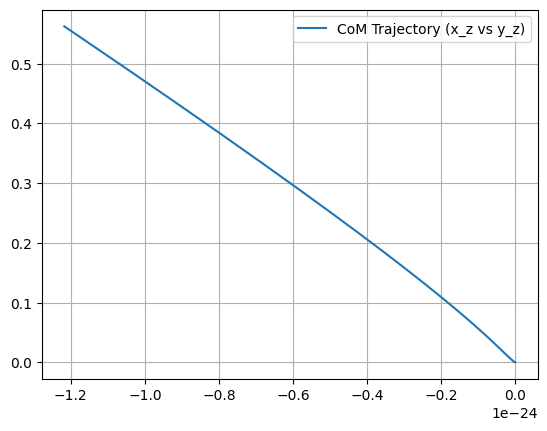

In [ ]:
plt.plot(trajectory_x[:,0], trajectory_y[:,0], label='CoM Trajectory (x_z vs y_z)')
plt.grid(True)
plt.legend()
plt.show()

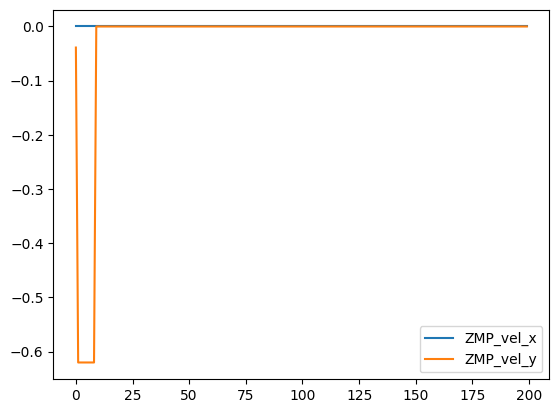

In [ ]:
plt.plot(optimal_ZMP_vel[:,0], label="ZMP_vel_x")
plt.plot(optimal_ZMP_vel[:,1], label="ZMP_vel_y")
plt.legend()        
plt.show()  